# 06 - Decision Framework

A guide you can actually follow, and a `coverage_report` you can run on your own data.

In [1]:
import sys
from pathlib import Path

_root = Path.cwd()
while not (_root / "pyproject.toml").exists() and _root != _root.parent:
    _root = _root.parent
if str(_root) not in sys.path:
    sys.path.insert(0, str(_root))

%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.artifacts import save_fig, save_json

plt.rcParams["figure.figsize"] = (7, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
NOMINAL = 0.90
SEED = 42

## Pick the method by your error structure and your stakes

| Situation | Use |
|---|---|
| Clean, constant-variance, roughly normal errors | Textbook normal interval - fine and cheap |
| Error size varies across the range | Quantile regression, GBM quantiles, or adaptive conformal |
| A model you cannot or will not retrain | Wrap it in split conformal (needs only a calibration set) |
| A coverage guarantee for a high-stakes decision | Conformal - the only method that provides one |
| **Always** | **Measure coverage on held-out data - an untested interval is decoration** |

In [2]:
from src.datasets.synthetic import make_synthetic
from src.evaluation.comparison import coverage_report
from src.intervals.normal import NormalInterval
from src.intervals.quantile_regression import QuantileRegressor
from src.intervals.gbm_quantile import GBMQuantileInterval
from src.intervals.conformal import SplitConformal, AdaptiveConformal
from src.visualisation import plot_coverage_bar

d = make_synthetic("heteroscedastic", 6000, SEED)
xt, yt, xe, ye = d.x[:4000], d.y[:4000], d.x[4000:], d.y[4000:]

fitted = {
    "normal": NormalInterval(coverage=NOMINAL).fit(xt, yt),
    "quantile_regression": QuantileRegressor(n_iter=1500).fit(xt, yt),
    "gbm_quantile": GBMQuantileInterval(n_estimators=150).fit(xt, yt),
    "split_conformal": SplitConformal(coverage=NOMINAL).fit(xt, yt),
    "adaptive_conformal": AdaptiveConformal(coverage=NOMINAL).fit(xt, yt),
}
report = coverage_report(fitted, xe, ye, nominal=NOMINAL)
report

,method,coverage,nominal,mean_width
0,normal,0.8810,0.9,15.006658
1,quantile_regression,0.9310,0.9,15.116728
2,gbm_quantile,0.9020,0.9,13.700224
3,split_conformal,0.9015,0.9,16.998269
4,adaptive_conformal,0.9295,0.9,15.729467


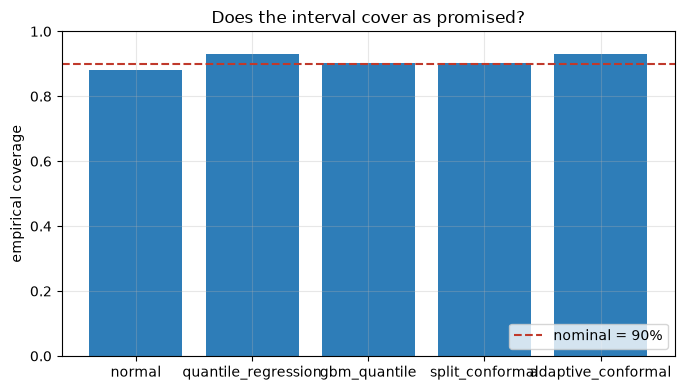

In [3]:
fig = plot_coverage_bar(report, nominal=NOMINAL)
save_fig(fig, "06_coverage_report")
plt.show()

In [4]:
decision_rules = [
    {"situation": "Clean, constant-variance, roughly normal errors",
     "recommendation": "Textbook normal interval - fine and cheap"},
    {"situation": "Error size varies across the range",
     "recommendation": "Quantile regression, GBM quantiles, or adaptive conformal"},
    {"situation": "A model you cannot or will not retrain",
     "recommendation": "Wrap it in split conformal (needs only a calibration set)"},
    {"situation": "A coverage guarantee for a high-stakes decision",
     "recommendation": "Conformal - the only method that provides one"},
    {"situation": "Always",
     "recommendation": "Measure coverage on held-out data; an untested interval is decoration"},
]
save_json("06_decision_framework", {
    "nominal_coverage": NOMINAL,
    "coverage_report": report.to_dict(orient="records"),
    "decision_rules": decision_rules,
})
for r in decision_rules:
    print(f"- {r['situation']}: {r['recommendation']}")

- Clean, constant-variance, roughly normal errors: Textbook normal interval - fine and cheap
- Error size varies across the range: Quantile regression, GBM quantiles, or adaptive conformal
- A model you cannot or will not retrain: Wrap it in split conformal (needs only a calibration set)
- A coverage guarantee for a high-stakes decision: Conformal - the only method that provides one
- Always: Measure coverage on held-out data; an untested interval is decoration


The rule that outranks all the others: **always measure coverage on held-out data.**
An interval you have not coverage-tested is decoration, not information.